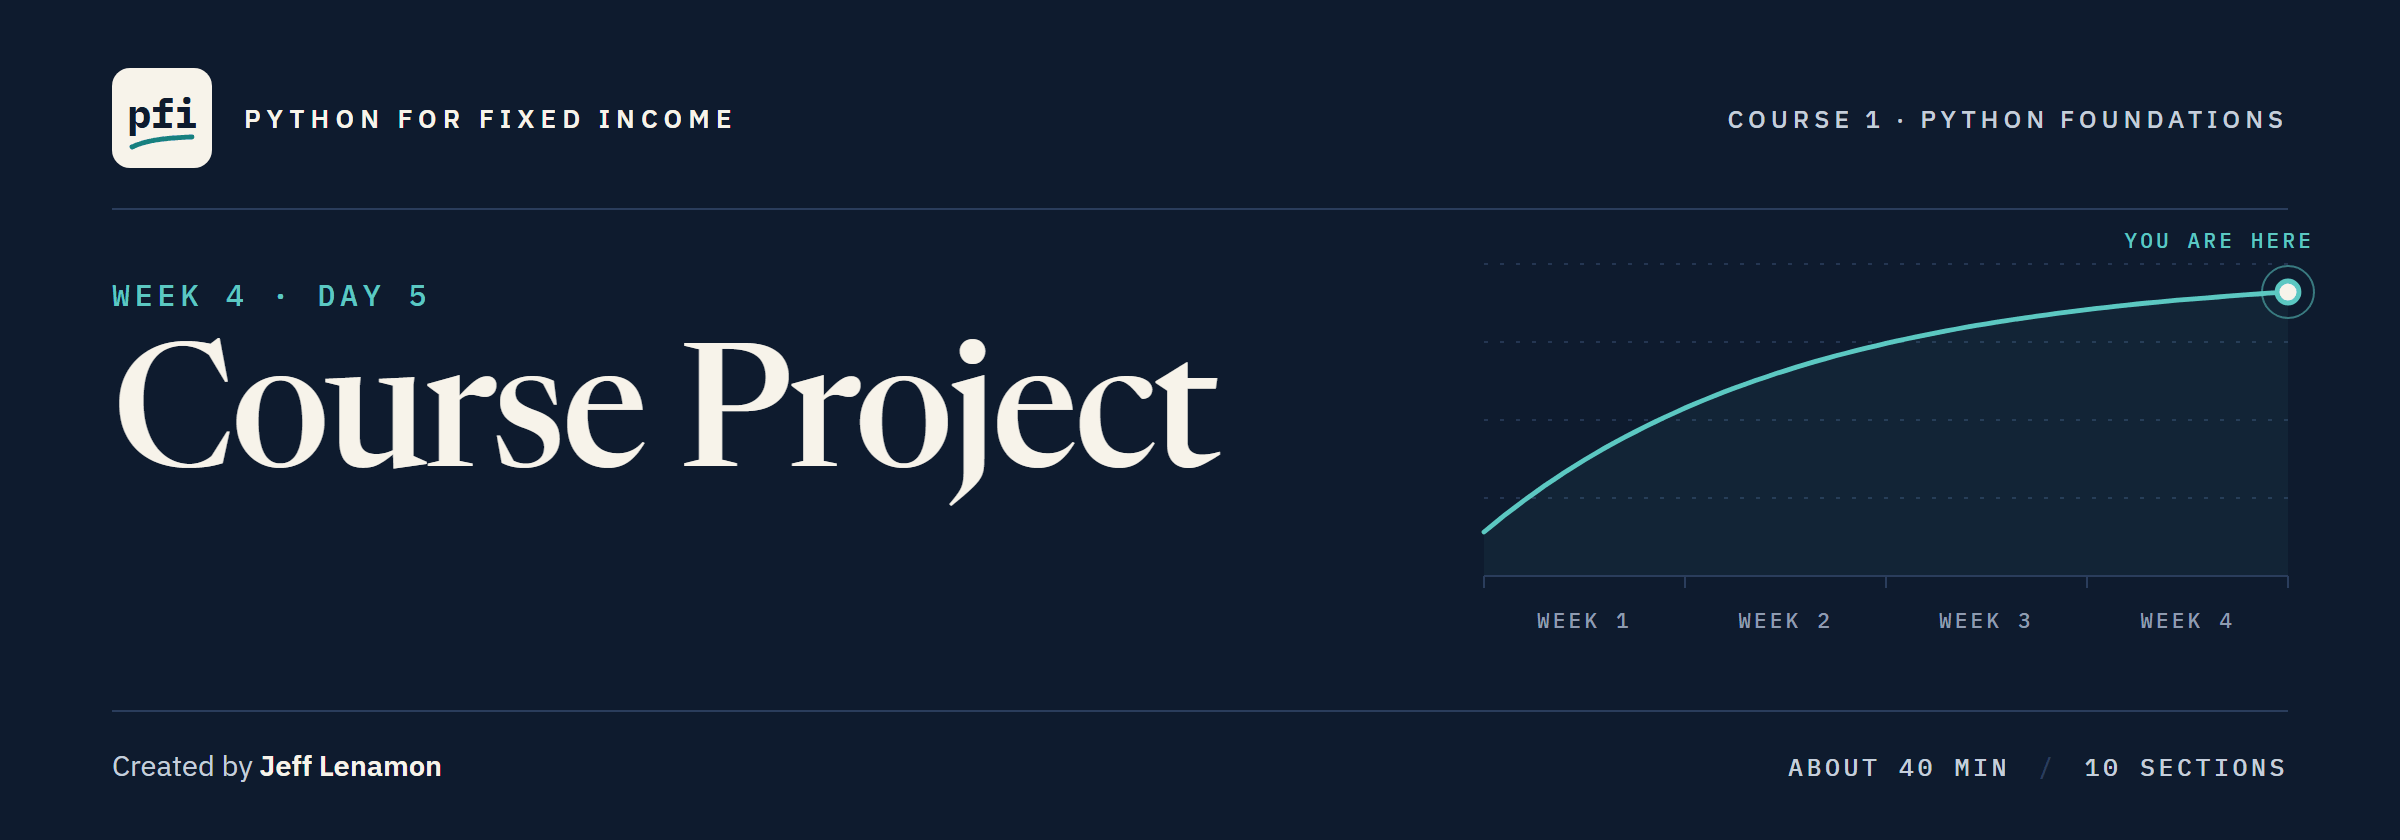

# Course Project

Week 4, Day 5. A new month-end extract is tested against its cover note, cleaned by a function you write, described, compared with its benchmark, and written up for the portfolio manager. You write the code.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week4/day5/course1_project.ipynb)

## The Brief

### The Desk Lead's Note

> Operations sent October's extract with a cover note. Before any number leaves the desk, tell me whether it can be trusted: fix what you can prove, in one function, so November is one call. Then tell me what is in the book, where it is concentrated, and how it differs from the benchmark. Send me a workbook and one page. Describe it: no views on any bond, issuer, or sector.

September's faults say nothing about October's, and every name is invented.

### The Cover Note

```
To: Credit desk
From: Operations
Subject: Month-end holdings extract, as of 2026-10-30

The month-end extract is attached as project_holdings.csv.

Control totals for the book:
  Number of bonds:      206
  Total face:           507,250,000 dollars
  Total market value:   509,928,477.50 dollars

Market value is face times clean price plus accrued interest, divided by 100.
All positions are priced as of 2026-10-30.
Please tell us if the extract does not agree with these totals.
```

It is also `data/project_cover_note.txt`.

### The Project on One Page

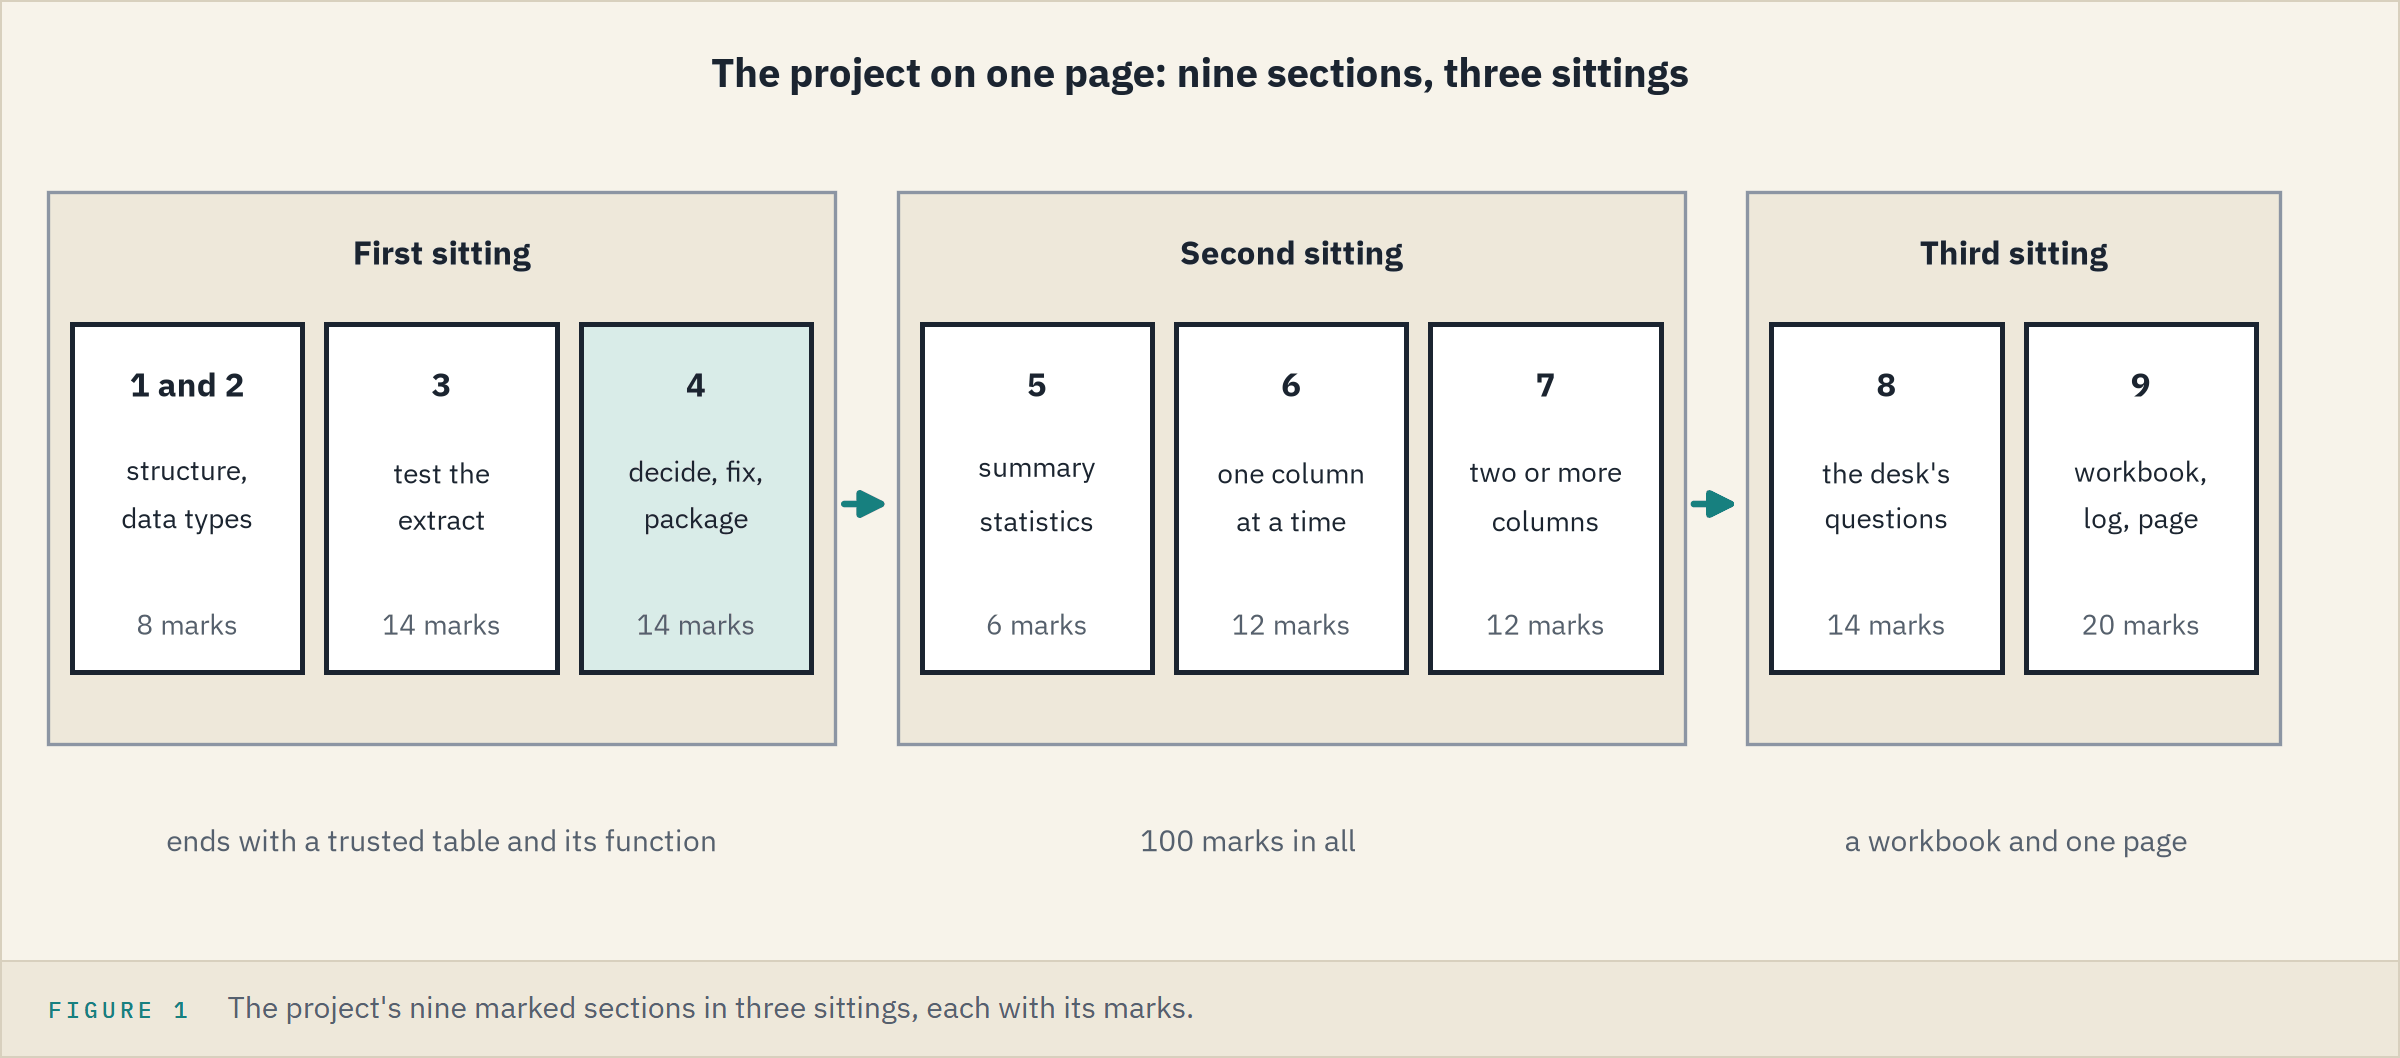

**Nine sections, three sittings, and one page at the end. The file comes first.**

### The Rules

1. **Work in a copy:** fixes go to `book`, never to `raw`.
2. **State every decision** in a markdown cell: what, how many rows, what evidence.
3. **Print `headline()` before and after every fix.**
4. **Describe:** never recommend, rank, or forecast.
5. **Finish every chart:** title, labelled axes, units.
6. **Restart and Run All** before you hand in.
7. **Check any AI answer** as week 1's Day 1, Working With an AI Assistant, taught: read, predict, run, check; log it for 9.2.

### How the Work Is Read and Checked

The picture's marks show the weight; a number with no sentence earns part of its mark.
Each **Observations** cell in sections 5 to 8 wants each figure with its unit and bond count.
Each `check()` prints `correct`, `not yet`, or `not attempted yet`; round as each question asks.
The checkpoint after 4.1 must pass before section 5.
Worked answers: `course1_project_solutions.ipynb`, once your page is written.

## The Data

Units: `coupon` and `yield_pct` in percent, `oas` in basis points, `duration` in years, `price` and `accrued` per 100 of face, and `par_held`, `amount_outstanding`, and `market_value` in dollars.

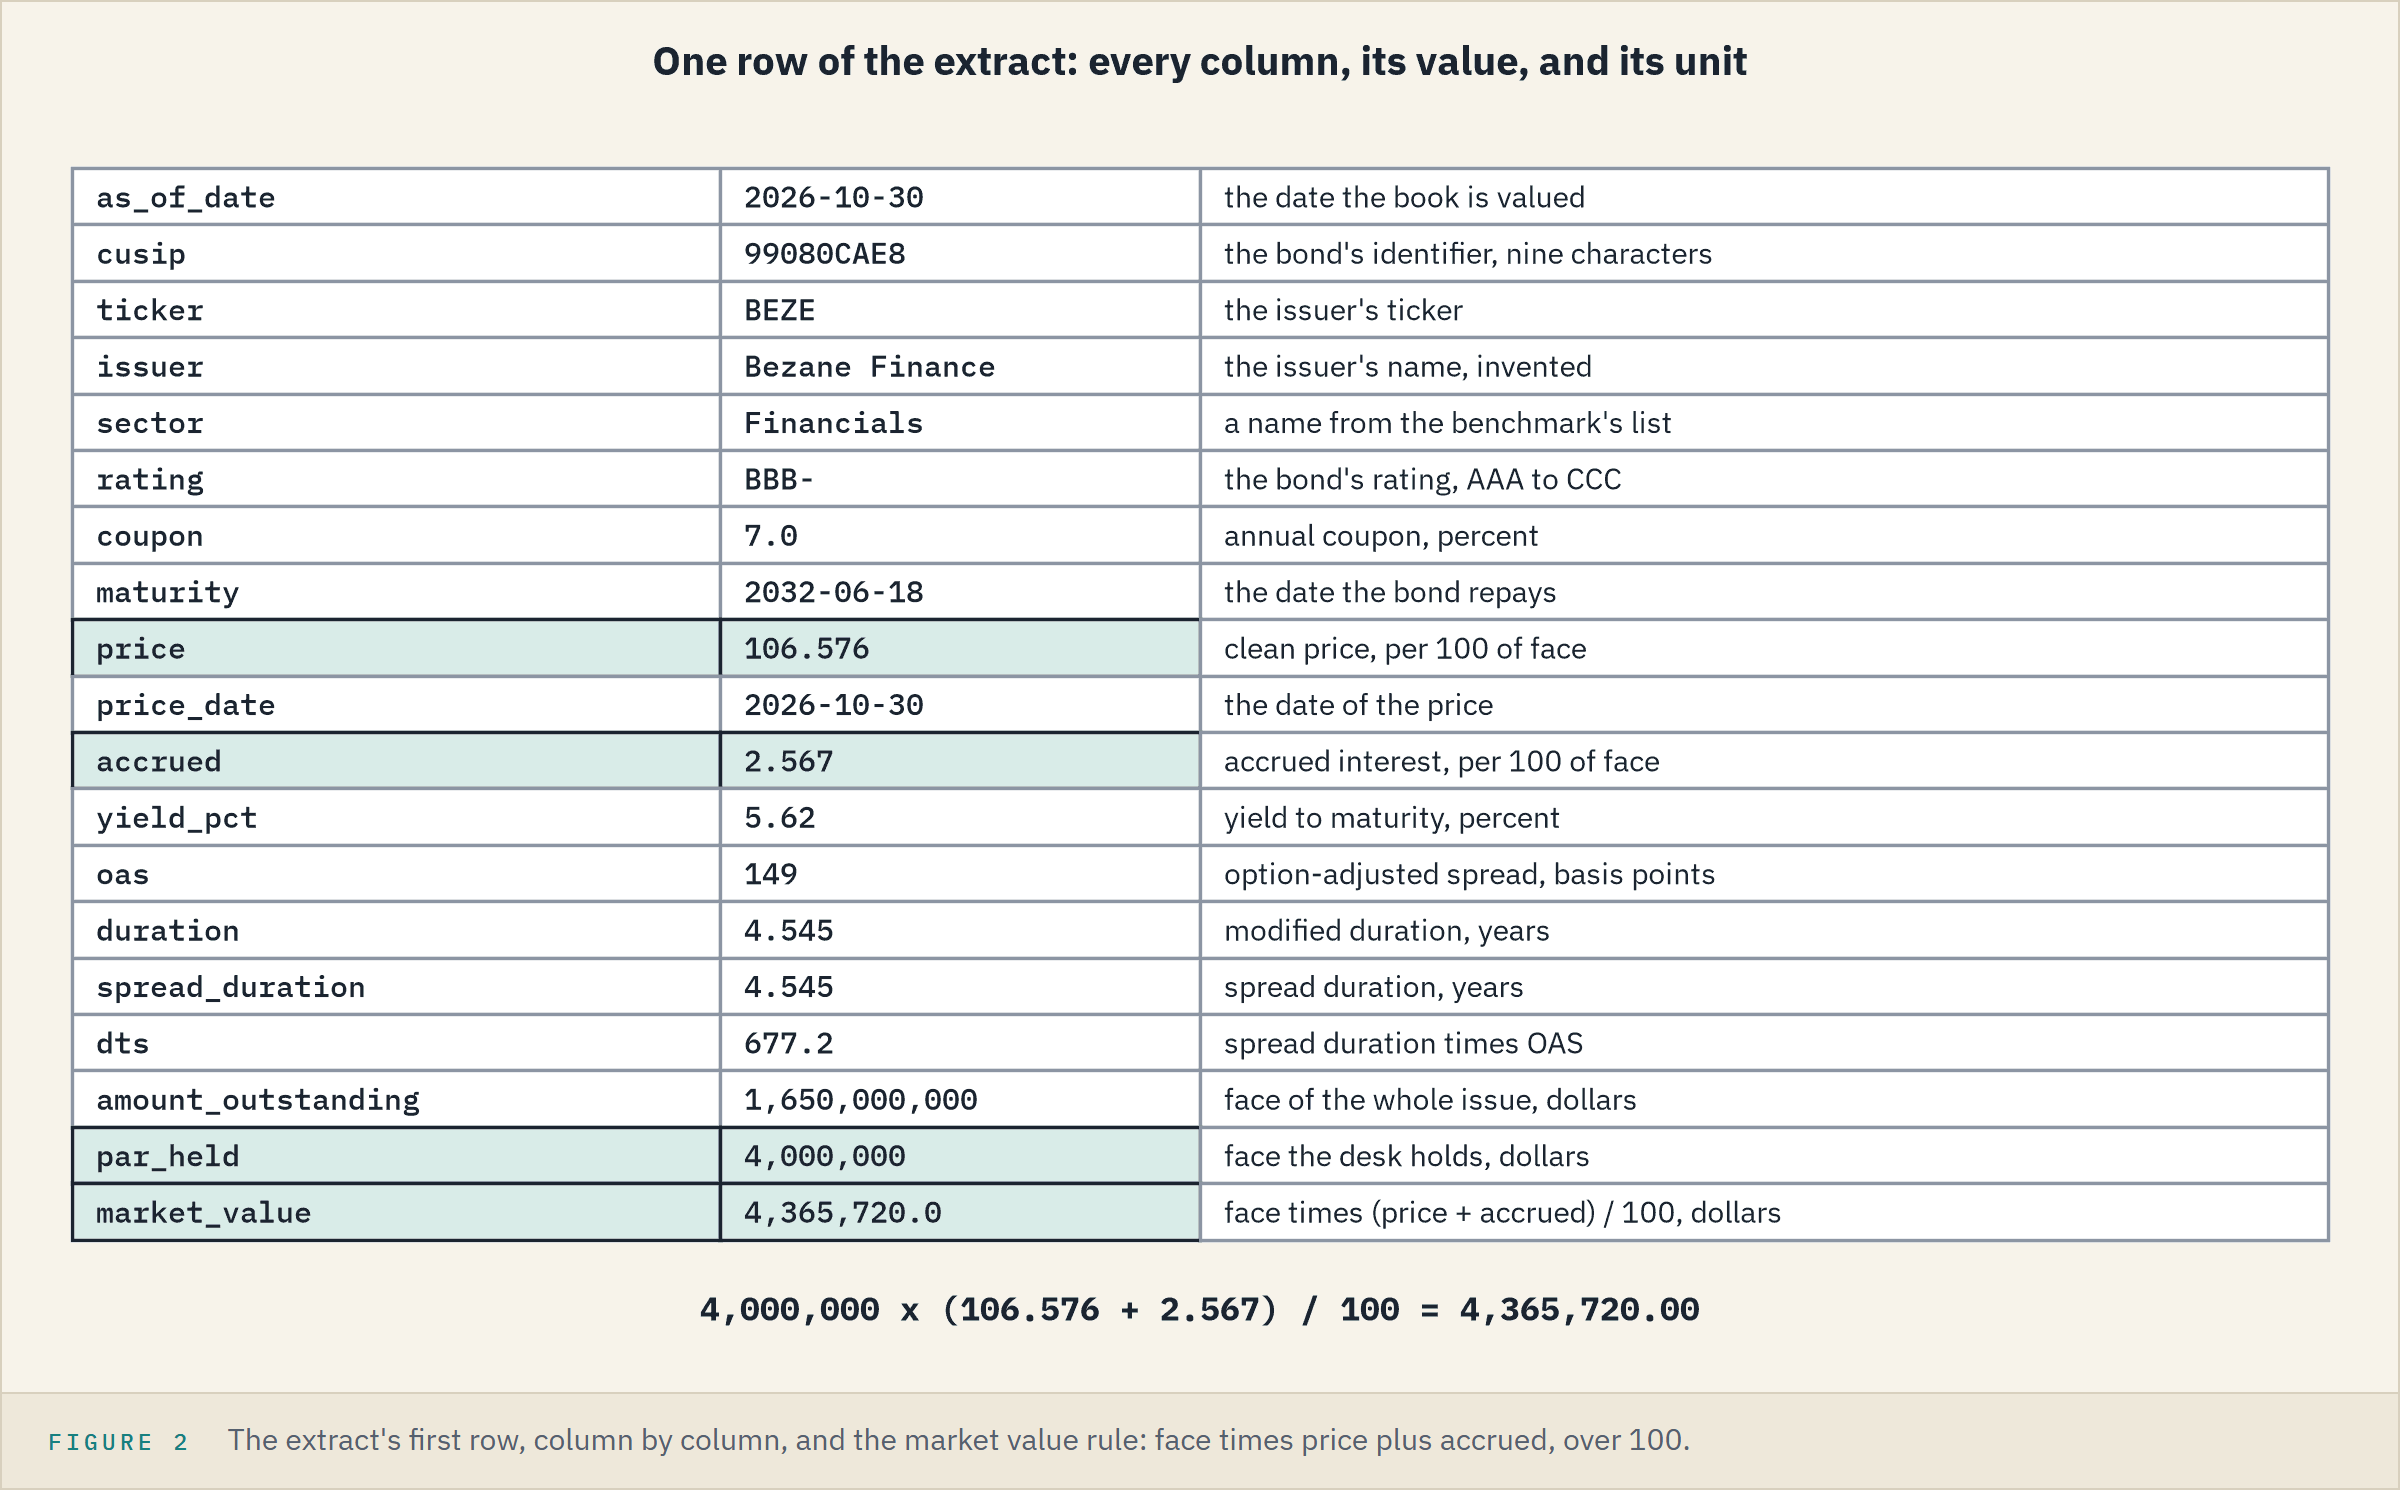

`ratings.csv` is the rating scale: `rating`, `score` (1 for AAA to 18 for CCC), `bucket`, and `grade`.
`benchmark.csv` holds 821 bonds, a `weight_pct` for each, and no `par_held`.

**The benchmark is September's file, a month older than the book: say so wherever they meet.**

## Setup

Run the next three cells first, and do not change them: they load the files, store the cover note's totals, and define `headline()` and `check()`.

In [1]:
import os

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# the house greens and greys, as in the Visualization notebook
sns.set_theme(style='whitegrid', palette=['#2E7D5B', '#9AA5B1', '#1E4D3A', '#52606D'])

In [2]:
# the repo's data folder on your machine; in Colab, GitHub, as in pandas Part 1
if os.path.exists('../../../data/project_holdings.csv'):
    data_folder = '../../../data/'
else:
    data_folder = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/'
# raw is the extract exactly as it arrived: nothing you write changes it
raw = pd.read_csv(data_folder + 'project_holdings.csv')
ratings = pd.read_csv(data_folder + 'ratings.csv')
benchmark = pd.read_csv(data_folder + 'benchmark.csv')
# the cover note's control totals
expected_bonds = 206
expected_face = 507_250_000
expected_value = 509_928_477.50


def headline(label, table):
    # the headline numbers, printed before and after every fix, as in the EDA notebook
    print(f"{label}: {len(table):,} rows | face {table['par_held'].sum():,} | "
          f"market value {table['market_value'].sum():,.2f} | mean OAS {table['oas'].mean():.2f}")


print('ratings', ratings.shape, '| benchmark', benchmark.shape)

ratings (18, 4) | benchmark (821, 19)


In [3]:
# check() compares a fingerprint of your answer with a stored one, so no answer is written here
import hashlib


def check(label, answer, code, places=None):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    # a number is rounded to the places the question asks for, so 7 and 7.0 read the same
    if places is not None:
        answer = round(float(answer), places)
    text = label + '|' + str(answer).strip().lower()
    # hashlib.sha256() makes a fingerprint that cannot be turned back into the answer;
    # .encode() turns the text into bytes for it, and .hexdigest() writes it as letters and digits
    if hashlib.sha256(text.encode()).hexdigest()[:12] == code:
        print(label + ': correct')
    else:
        print(label + ': not yet. You have ' + str(answer))

## Your Route Through Day 5

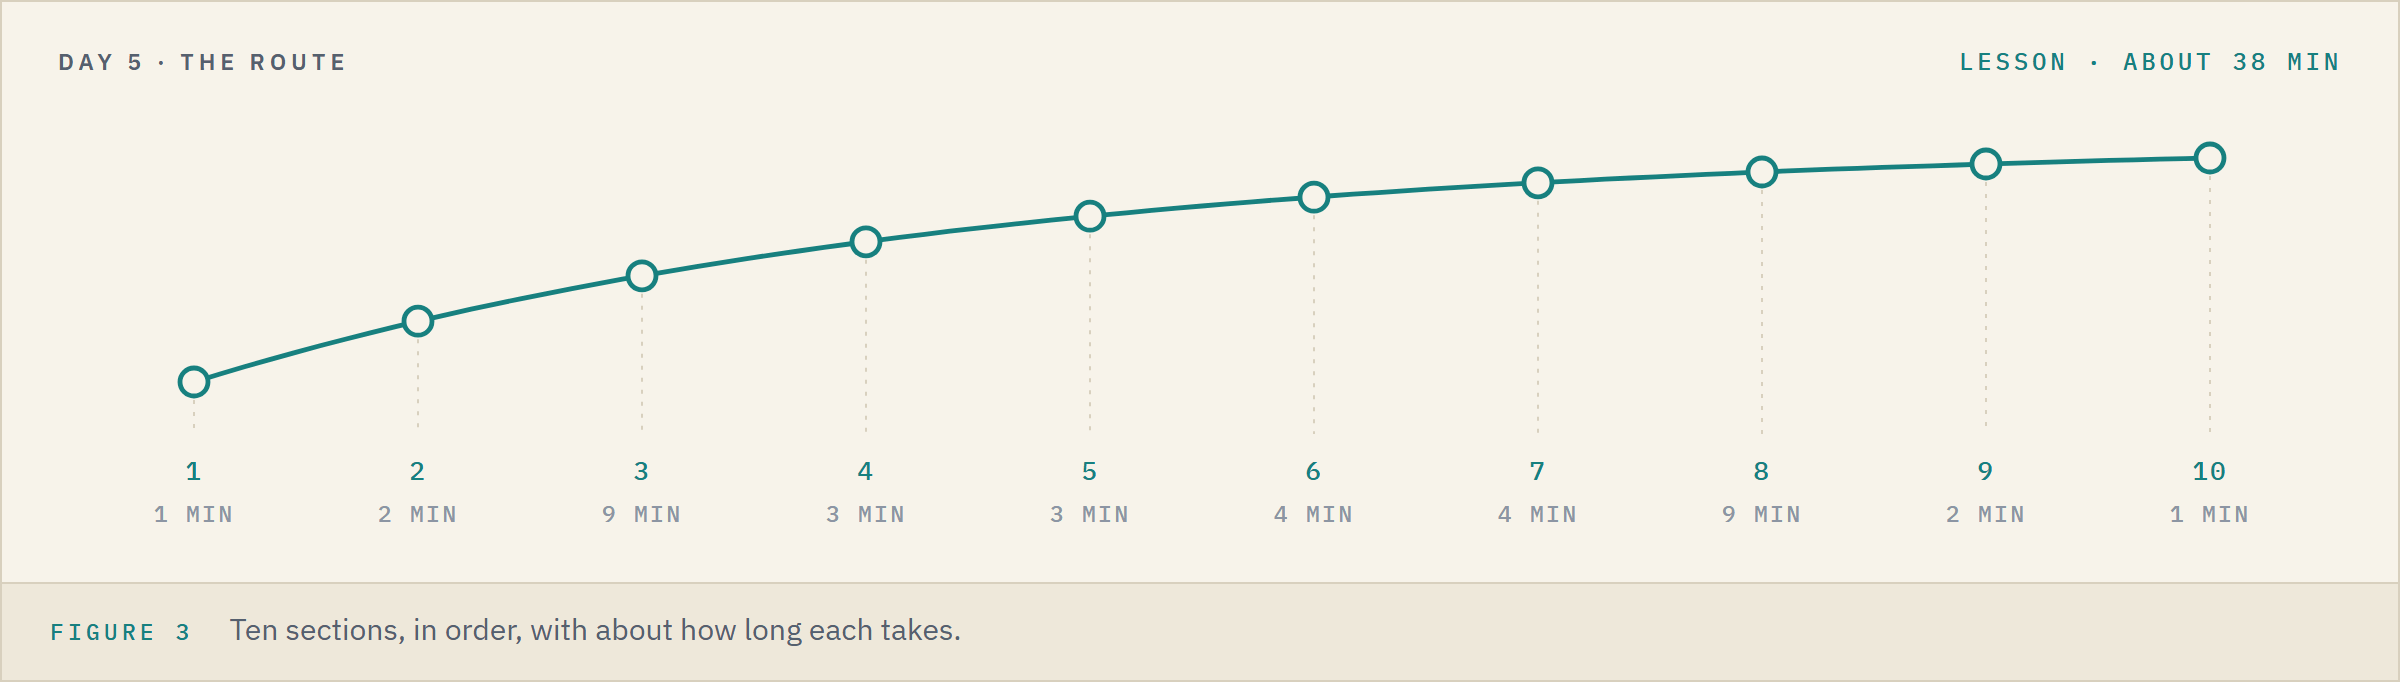

<table align="left">
<tr><th align="left"></th><th align="left">Section</th><th align="left">About</th></tr>
<tr><td align="left">1</td><td align="left">The Structure of the Data</td><td align="left">1 min</td></tr>
<tr><td align="left">2</td><td align="left">Data Types</td><td align="left">2 min</td></tr>
<tr><td align="left">3</td><td align="left">Data Quality: Test the Extract</td><td align="left">9 min</td></tr>
<tr><td align="left">4</td><td align="left">Data Quality: Decide, Fix, and Package</td><td align="left">3 min</td></tr>
<tr><td align="left">5</td><td align="left">Summary Statistics</td><td align="left">3 min</td></tr>
<tr><td align="left">6</td><td align="left">One Column at a Time</td><td align="left">4 min</td></tr>
<tr><td align="left">7</td><td align="left">Two or More Columns</td><td align="left">4 min</td></tr>
<tr><td align="left">8</td><td align="left">The Desk's Questions</td><td align="left">9 min</td></tr>
<tr><td align="left">9</td><td align="left">The Deliverables</td><td align="left">2 min</td></tr>
<tr><td align="left">10</td><td align="left">Before You Hand In</td><td align="left">1 min</td></tr>
</table>
<br clear="left">

**Time.** About 38 minutes for the lesson.

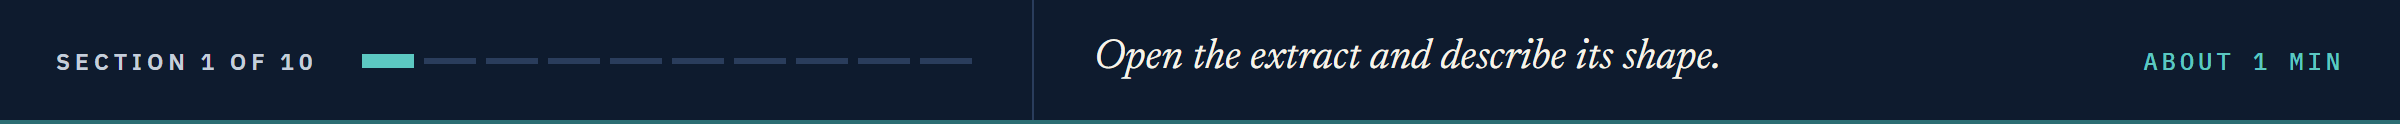

## 1 The Structure of the Data

Tools: `.shape` and `.head()` (week 1's Day 5), `nunique()` (pandas Part 2).

### 1.1 Rows, Columns, and Identifiers

Q. What shape is the extract (**answer_1_1a**), and what is one row? Show the first rows, and count the different as-of dates, CUSIPs (**answer_1_1b**), tickers, and issuers.

**Write down the row count: the cover note says 206.**

In [4]:
# your code here
answer_1_1a = ...
answer_1_1b = ...

check('Question 1.1 shape', answer_1_1a, 'efc00d12fce0')
check('Question 1.1 CUSIPs', answer_1_1b, '8e37a58aa0ec', places=0)

Question 1.1 shape: not attempted yet
Question 1.1 CUSIPs: not attempted yet


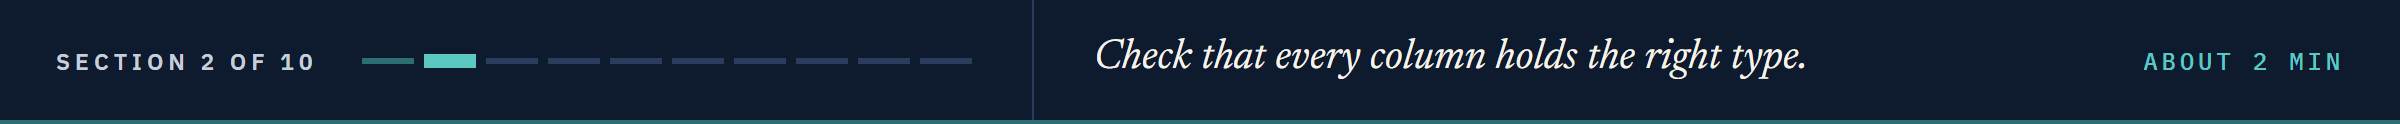

## 2 Data Types

Tools: `dtypes` (pandas Part 1), `describe()` (week 1's Day 5), `.copy()` (pandas Part 2), `pd.to_datetime(errors='coerce')` (the EDA notebook), `.date()` (A First Look at the Data).

### 2.1 The Type of Each Column

Q. Which types did pandas give the columns? How many are numbers (**answer_2_1**), and which hold dates?

In [5]:
# your code here
answer_2_1 = ...

check('Question 2.1', answer_2_1, '8ed934a15453', places=0)

Question 2.1: not attempted yet


### 2.2 A Working Copy With Real Dates

Q. Copy `raw` to `book` and convert its three date columns. How many dates could not be read (**answer_2_2**)? Print each column's earliest and latest.

**From here on every fix goes to `book`.**

In [6]:
# your code here
book = ...
answer_2_2 = ...

check('Question 2.2', answer_2_2, 'eae021f63e10', places=0)

Question 2.2: not attempted yet


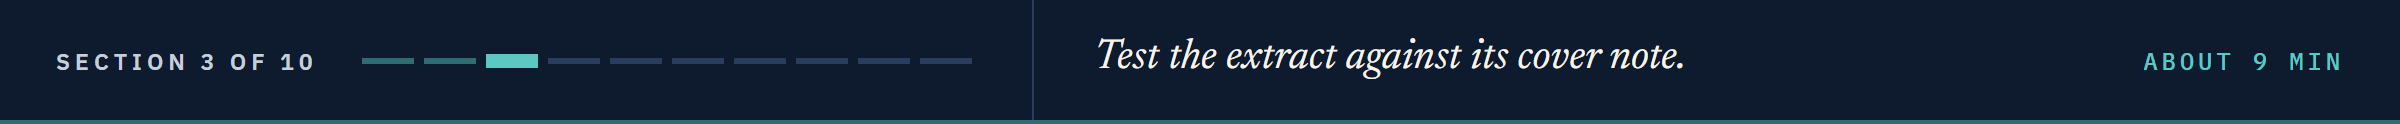

## 3 Data Quality: Test the Extract

No list of faults comes with this file.
**Test it against the cover note and the rules: fix what is an error, flag what you cannot fix, keep what is real.**

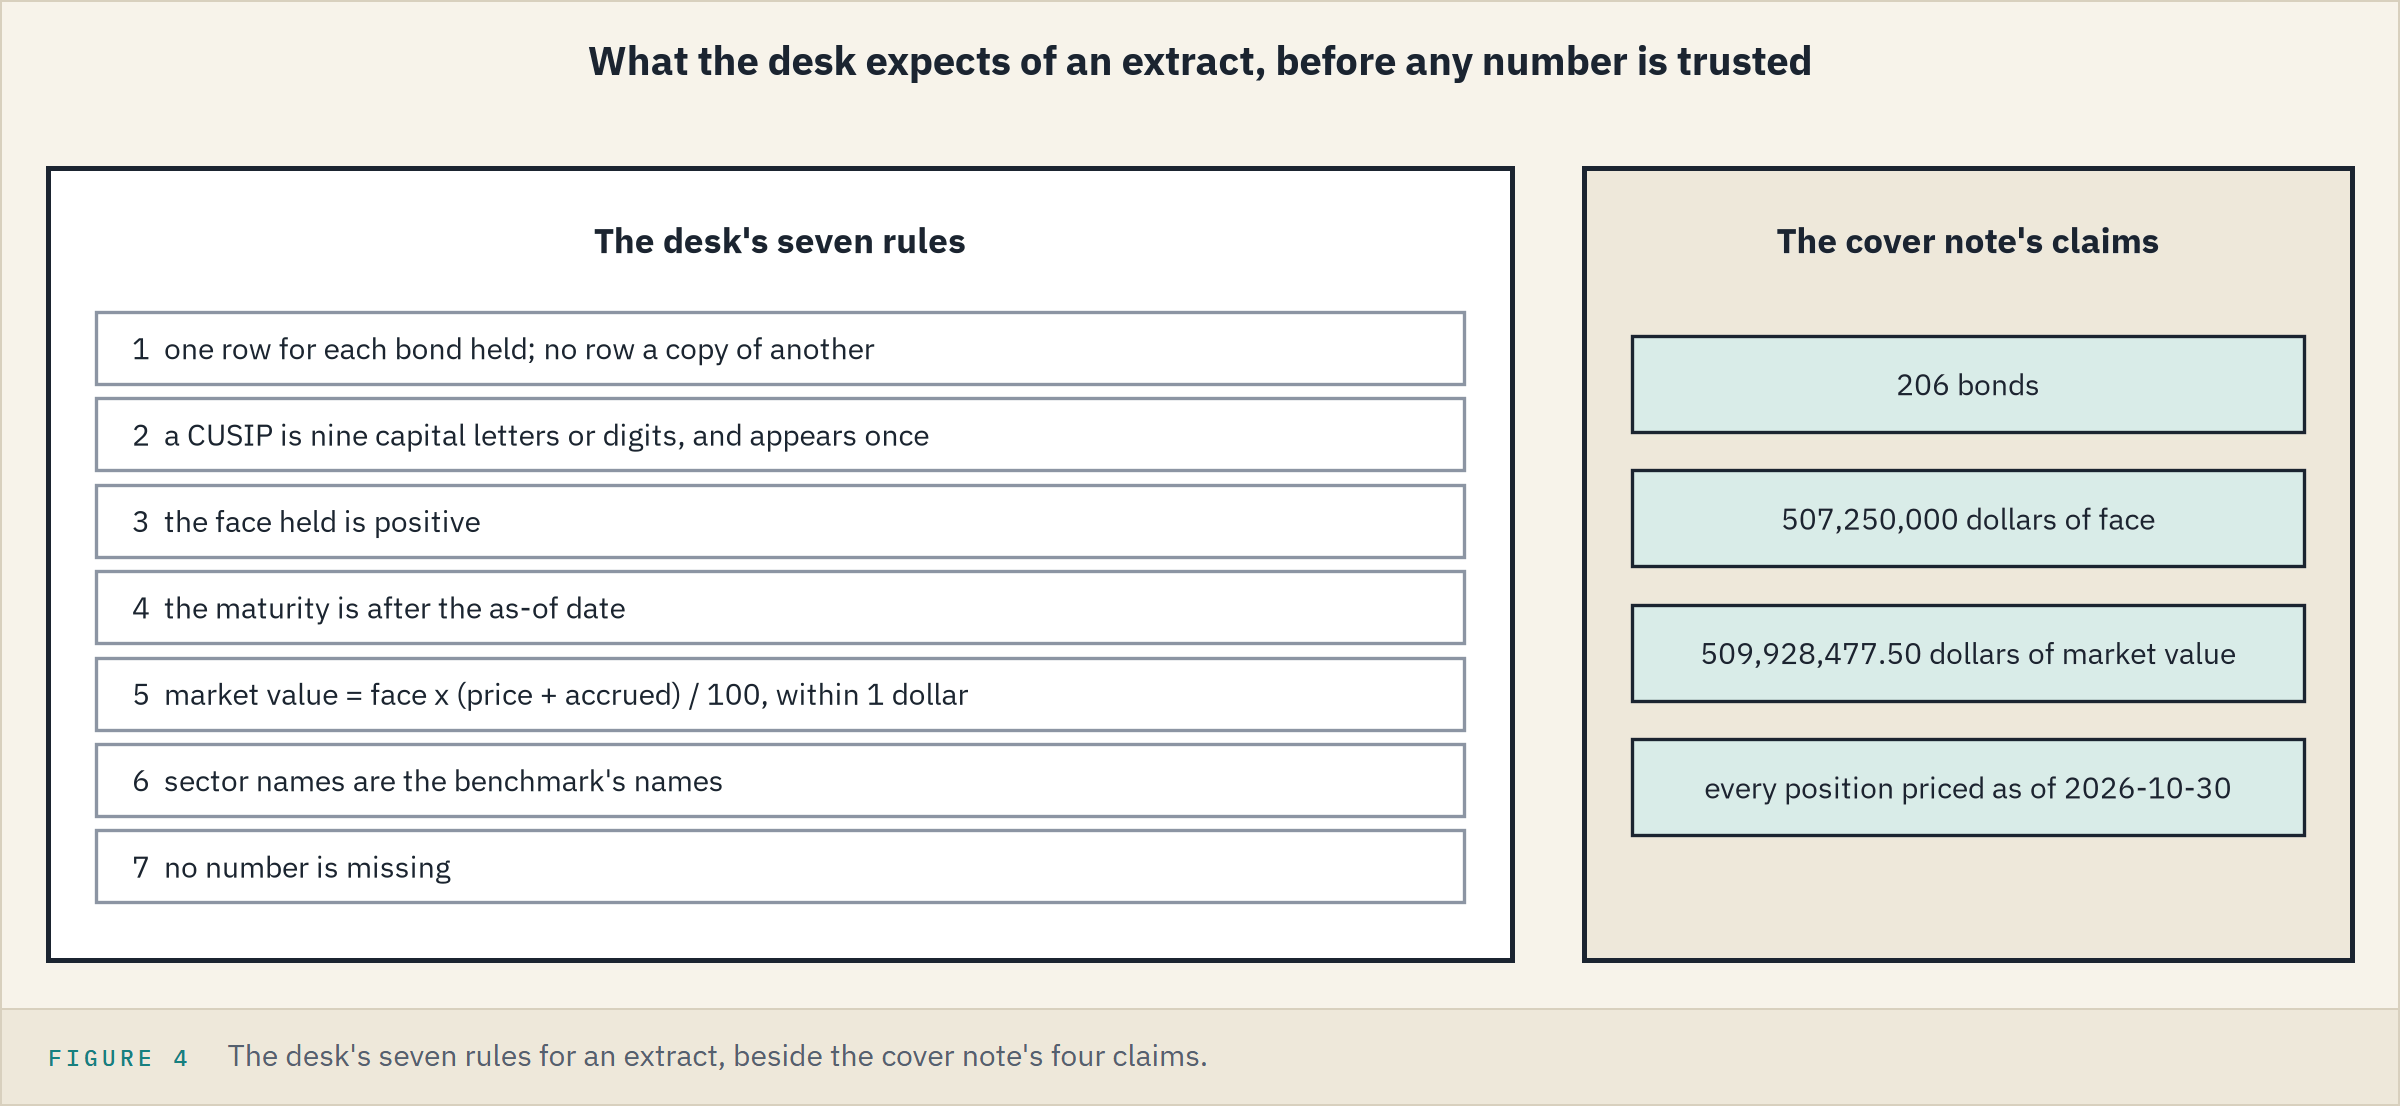

Count on `book` as 2.2 left it, and fix nothing until section 4.
A Stuck block holds the checkpoint's decision: open it after your own.

Tools: `duplicated(keep=False)`, `.str.strip()`, `.str.title()`, `isin()`, `.abs()`, `dropna()` (the EDA notebook); `.str.fullmatch()` (Analyzing Text Part 1); `set()` (Analyzing Text Part 2); `~` (A First Look at the Data); `axis=1` (NumPy Part 2).

**Excel side by side.** CUSIP in B, sector E, price I, accrued K, OAS M, face R, value S.

<table align="left">
<tr><th align="left">Rule</th><th align="left">Excel, any current version</th></tr>
<tr><td align="left">1</td><td align="left"><code>=COUNTIF($B$2:$B$210, B2) &gt; 1</code> marks rows sharing a CUSIP</td></tr>
<tr><td align="left">2</td><td align="left"><code>=LEN(B2) = 9</code> tests only the length</td></tr>
<tr><td align="left">3</td><td align="left"><code>=COUNTIF(R2:R210, "&lt;=0")</code></td></tr>
<tr><td align="left">5</td><td align="left"><code>=ABS(R2 * (I2 + K2) / 100 - S2) &gt; 1</code> filled down</td></tr>
<tr><td align="left">6</td><td align="left"><code>=COUNTIF(benchmark!$E$2:$E$822, E2) = 0</code> ignores capitals, so it misses names <code>isin()</code> catches</td></tr>
<tr><td align="left">7</td><td align="left"><code>=COUNTBLANK(M2:M210)</code></td></tr>
</table>
<br clear="left">

**Every rule gets a count: failures are the fix list, passes go in the page.**

### 3.1 The File Against the Cover Note

Q. Print the headline as received and the file less the cover note in rows (**answer_3_1**), face, and value. What do the three suggest?

In [7]:
# your code here
answer_3_1 = ...

check('Question 3.1', answer_3_1, '937c431e769f', places=0)

Question 3.1: not attempted yet


### 3.2 Rule 1: One Row for Each Bond

Q. How many rows copy an earlier row exactly (**answer_3_2**)? Show each beside its original, with the face and value they carry.

<details><summary>Stuck? The expected decision</summary>

Remove exact copies, keeping the first of each, and renumber the rows.

</details>

In [8]:
# your code here
answer_3_2 = ...

check('Question 3.2', answer_3_2, '68eb8d661dc0', places=0)

Question 3.2: not attempted yet


### 3.3 Rule 2: Identifiers

Q. How many CUSIPs fail a pattern of nine capital letters or digits (**answer_3_3a**), and how many are **not** in the benchmark (**answer_3_3b**)? Is any CUSIP there twice with different values?

In [9]:
# your code here
answer_3_3a = ...
answer_3_3b = ...

check('Question 3.3 shape', answer_3_3a, '62a24f0a3305', places=0)
check('Question 3.3 benchmark', answer_3_3b, '49f7ac431691', places=0)

Question 3.3 shape: not attempted yet
Question 3.3 benchmark: not attempted yet


### 3.4 Rule 3: The Face Held

Q. How many rows break rule 3 (**answer_3_4**)? Show them with price, accrued, face, and market value.

<details><summary>Stuck? The expected decision</summary>

If the market value fits the positive face, the sign is the error: make the face positive.

</details>

In [10]:
# your code here
answer_3_4 = ...

check('Question 3.4', answer_3_4, 'b8711bc55ec3', places=0)

Question 3.4: not attempted yet


### 3.5 Rule 4: The Maturity

Q. How many rows break rule 4 (**answer_3_5**)? Show them with coupon, maturity, and duration.

<details><summary>Stuck? The expected decision</summary>

Use the benchmark's maturity for the same CUSIP, once its ticker and coupon agree.

</details>

In [11]:
# your code here
answer_3_5 = ...

check('Question 3.5', answer_3_5, '9b6cbc9b0cc7', places=0)

Question 3.5: not attempted yet


### 3.6 Rule 5: The Tie-Out

Q. In how many rows is face times (price plus accrued) over 100 more than 1 dollar from `market_value` (**answer_3_6**)? Which column looks wrong in each?

<details><summary>Stuck? The expected decision</summary>

A wrong face is 3.4's case.

A price with its decimal point out of place, against the price that value, face, and accrued imply, goes back to per 100 of face, to 3 places.

</details>

In [12]:
# your code here
answer_3_6 = ...

check('Question 3.6', answer_3_6, 'd80dba792a53', places=0)

Question 3.6: not attempted yet


### 3.7 Rule 6: Sector Names

Q. How many rows have a `sector` that is not exactly a benchmark name (**answer_3_7**)? Print them so an end space would show.

<details><summary>Stuck? The expected decision</summary>

A name off only in capitals or end spaces is that sector: strip it, capitalize each word, and compare the sets of names.

</details>

In [13]:
# your code here
answer_3_7 = ...

check('Question 3.7', answer_3_7, '1b007be9b4e9', places=0)

Question 3.7: not attempted yet


### 3.8 Rule 7: Missing Numbers

Q. How many cells are missing (**answer_3_8a**), and what share of the cover note's value are their rows, percent to 2 places (**answer_3_8b**)? What would dropping them do? Do the gaps share anything?

<details><summary>Stuck? The expected decision</summary>

Drop no row: a missing OAS is `dts / spread_duration`, rounded to a basis point.

Test that on the complete rows first, then make the column whole numbers again.

</details>

In [14]:
# your code here
answer_3_8a = ...
answer_3_8b = ...

check('Question 3.8 missing cells', answer_3_8a, '42cf353ad1b9', places=0)
check('Question 3.8 share', answer_3_8b, 'e3f4ef2ffa88', places=2)

Question 3.8 missing cells: not attempted yet
Question 3.8 share: not attempted yet


### 3.9 Price Dates and Six More Tests

Q. How many rows are not priced on the as-of date (**answer_3_9a**)? Total the breaks of six tests (**answer_3_9b**): a price, coupon, or duration of zero or less; face above the amount outstanding; a rating off the scale; an untidy ticker.

In [15]:
# your code here
answer_3_9a = ...
answer_3_9b = ...

check('Question 3.9 price dates', answer_3_9a, 'adc58bb8921d', places=0)
check('Question 3.9 six tests', answer_3_9b, '30a63952bf8a', places=0)

Question 3.9 price dates: not attempted yet
Question 3.9 six tests: not attempted yet


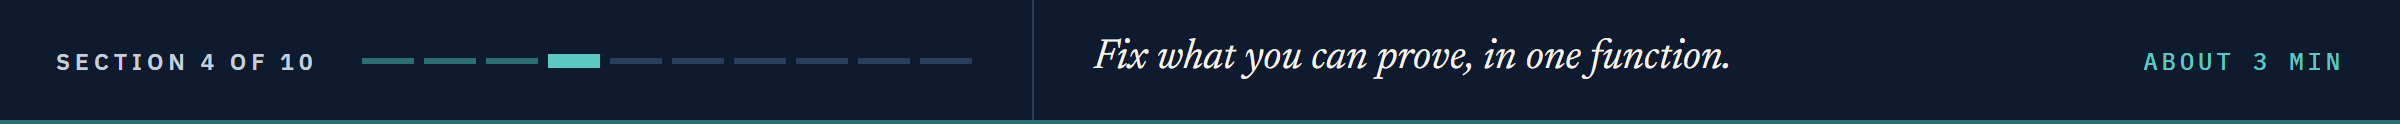

## 4 Data Quality: Decide, Fix, and Package

Tools: `drop_duplicates()`, `fillna()` (the EDA notebook); `.loc[mask, column] =`, `reset_index(drop=True)` (pandas Part 2); `.astype(int)` (the Treasury case study); `.map()` (the Consumer Credit case study); `def` (week 1's Day 1 Part 2); `assert` (week 1's Day 3); a function checked by its totals (From Notebook to Module).

### 4.1 Decide and Fix

Q. Sort each failing row into the EDA notebook's three kinds: fix, flag, or keep. Give each fix a decision cell, then make it with `headline()` before and after. Rerun 3.2 to 3.9: how many rows still fail (**answer_4_1**)?

In [16]:
# your code here: a decision cell and a fix cell for each fix
answer_4_1 = ...

check('Question 4.1', answer_4_1, 'acca33222a1d', places=0)

Question 4.1: not attempted yet


### Checkpoint: the Cleaned Table

Q. Does `book` match the cover note and the expected decisions? If a line is not `correct`, open that part's Stuck block.

In [17]:
# the cleaned book against the cover note and the decisions the worked version made
if book is ...:
    print('Checkpoint: not attempted yet')
else:
    check('Checkpoint rows', len(book), 'd5ed44cc564e', places=0)
    check('Checkpoint face', book['par_held'].sum(), '254fb34186a5', places=0)
    check('Checkpoint market value', book['market_value'].sum(), '5c6137e7ec20', places=2)
    check('Checkpoint different sectors', book['sector'].nunique(), 'c7854488271a', places=0)
    check('Checkpoint missing cells', book.isna().sum().sum(), '53b200a15764', places=0)
    check('Checkpoint mean OAS', book['oas'].mean(), '35ec3732ae02', places=2)
    check('Checkpoint mean price', book['price'].mean(), 'cd707ccf0646', places=3)
    check('Checkpoint raw is unchanged', raw.shape, '9aa4001604ba')

Checkpoint: not attempted yet


### The Three Gaps, Closed

Q. Did every gap to the cover note reach zero? This cell is written for you.

In [18]:
# written for you: each total against the cover note, in percent (Analyzing Text Part 2's .div)
if book is ...:
    print('Chart: not attempted yet')
else:
    received = [len(raw), raw['par_held'].sum(), raw['market_value'].sum()]
    now = [len(book), book['par_held'].sum(), book['market_value'].sum()]
    totals = pd.DataFrame({'as received': received, 'now': now}, index=['bonds', 'face', 'value'])
    gaps = totals.div([expected_bonds, expected_face, expected_value], axis=0) * 100 - 100
    chart = gaps.plot.bar(rot=0, ylim=(-0.2, 1.7), title='Each Total Less the Cover Note',
                          ylabel='Percent of the cover note')
    for bars in chart.containers:
        chart.bar_label(bars, fmt='%.2f')
    plt.show()

Chart: not attempted yet


### 4.2 The Cleaning as a Function

Q. Write `clean_extract(raw)`, its docstring listing 2.2's dates and 4.1's fixes in order, leaving its input unchanged; a second table it needs is a second parameter. Store its result in **cleaned**, `assert` the three totals with messages, and show `cleaned` equals `book`.

**The extract ties to its cover note, and one call rebuilds it. The first sitting ends here.**

In [19]:
# your code here
cleaned = ...

if cleaned is ...:
    print('Question 4.2: not attempted yet')
else:
    check('Question 4.2 rows', len(cleaned), 'e5178efc63d4', places=0)
    check('Question 4.2 face', cleaned['par_held'].sum(), '6613f6221e2c', places=0)
    check('Question 4.2 market value', cleaned['market_value'].sum(), '6594eed8b78e', places=2)
    check('Question 4.2 mean OAS', cleaned['oas'].mean(), 'f3ba04a128b9', places=2)
    check('Question 4.2 mean price', cleaned['price'].mean(), 'ef25b86639bb', places=3)
    check('Question 4.2 same as book', cleaned.equals(book), '6466c1cc0468')

Question 4.2: not attempted yet


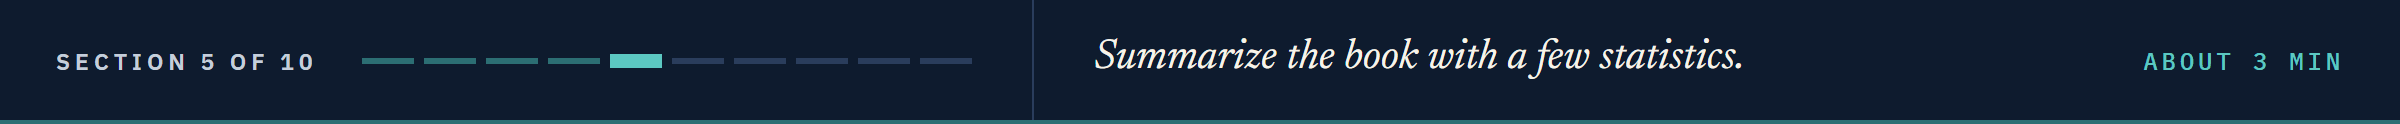

## 5 Summary Statistics

The second sitting, on `book` as at the checkpoint.

Tools: `pd.merge(validate=)` (Combining Part 1), `agg(['mean', 'median', 'skew'])` (the EDA notebook), `sns.countplot(order=)` and `bar_label()` (the Visualization notebook), `plt.subplots(1, 3)` (More Visualization).

### 5.1 The Rating Scale

Q. Join the scale's `score`, `bucket`, and `grade` to `book`, with rows before and after. How many bonds are High Yield (**answer_5_1**)?

In [20]:
# your code here
answer_5_1 = ...

check('Question 5.1', answer_5_1, 'c9f4439c8ead', places=0)

Question 5.1: not attempted yet


### 5.2 Summary, Mean, Median, and Skew

Q. Summarize `coupon`, `price`, `yield_pct`, `oas`, `duration`, and `market_value`: could a bond have each range? Give the median OAS to 1 place (**answer_5_2a**). Add `dts` and show mean, median, and skew: which column has the longest right tail, and which leans left? Give the OAS skew to 2 places (**answer_5_2b**).

In [21]:
# your code here
answer_5_2a = ...
answer_5_2b = ...

check('Question 5.2 median OAS', answer_5_2a, '0d93273ea756', places=1)
check('Question 5.2 skew', answer_5_2b, 'dfeb3da67e98', places=2)

Question 5.2 median OAS: not attempted yet
Question 5.2 skew: not attempted yet


#### Observations

*

### 5.3 Counts by Category

Q. Count bonds by sector, by bucket from AAA to CCC, and by grade, drawn as three labelled bar charts in a row. Which bucket is largest (**answer_5_3**)?

**Counts treat every bond alike; section 8 weighs them by value.**

In [22]:
# your code here
answer_5_3 = ...

check('Question 5.3', answer_5_3, '16e058800603')

Question 5.3: not attempted yet


#### Observations

*

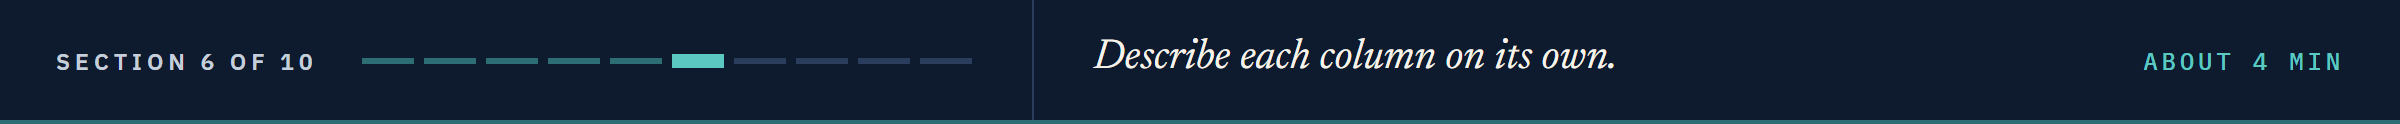

## 6 One Column at a Time

Tools: `ax.hist()`, `axvline(label=)`, `quantile()`, `ax.boxplot()` (the Visualization notebook); the IQR rule (the EDA notebook); `nlargest()` (pandas Part 2).

### 6.1 The Distribution of the OAS

Q. Draw a histogram of the OAS with labelled lines at the mean and median. How many bonds sit above the mean (**answer_6_1**)?

In [23]:
# your code here
answer_6_1 = ...

check('Question 6.1', answer_6_1, 'cda4c6348719', places=0)

Question 6.1: not attempted yet


#### Observations

*

### 6.2 The IQR Rule

Q. Print the OAS quartiles, IQR, and limits, and draw its box plot. Give the upper limit to 3 places (**answer_6_2a**) and the bonds above it (**answer_6_2b**).

In [24]:
# your code here
answer_6_2a = ...
answer_6_2b = ...

check('Question 6.2 upper limit', answer_6_2a, '6b59303d0caa', places=3)
check('Question 6.2 bonds flagged', answer_6_2b, 'cae9f4b76f82', places=0)

Question 6.2 upper limit: not attempted yet
Question 6.2 bonds flagged: not attempted yet


### 6.3 Errors or Real Bonds?

Q. Show the flagged bonds widest first with rating, coupon, price, yield, and OAS. Errors or real? Give the evidence and your decision. Give their share of value, percent to 2 places (**answer_6_3**).

<details><summary>Stuck? The expected decision</summary>

Nothing is deleted for being far: test each against its other columns, as in the EDA notebook's Far Is Not Wrong.

</details>

In [25]:
# your code here
answer_6_3 = ...

check('Question 6.3', answer_6_3, '6ec77e85b8db', places=2)

Question 6.3: not attempted yet


#### Observations

*

### 6.4 The Distribution of the Price

Q. Draw a histogram of the clean price with a line at par. How many are below 100 (**answer_6_4**)? Is the lowest or highest priced bond an error?

In [26]:
# your code here
answer_6_4 = ...

check('Question 6.4', answer_6_4, '1ba8d4146698', places=0)

Question 6.4: not attempted yet


#### Observations

*

### 6.5 The Size of the Positions

Q. Draw a histogram of market value in millions of dollars. What share is the largest position, percent to 2 places (**answer_6_5**)? Does the IQR rule flag any?

**Far is not wrong: every flagged bond is tested before it is judged.**

In [27]:
# your code here
answer_6_5 = ...

check('Question 6.5', answer_6_5, 'b905ffad5df0', places=2)

Question 6.5: not attempted yet


#### Observations

*

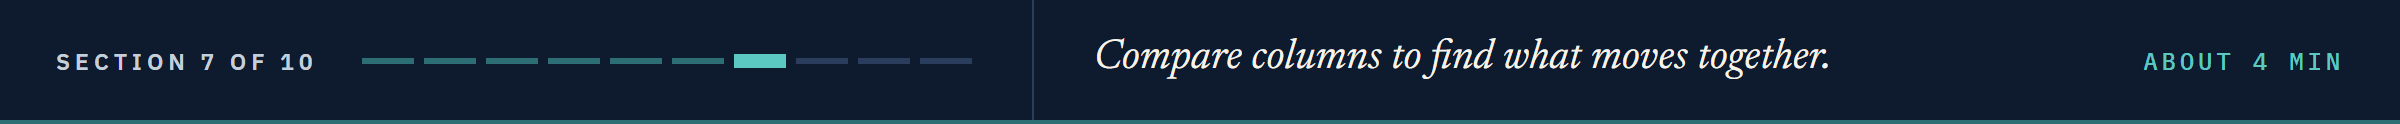

## 7 Two or More Columns

Tools: `.corr()`, `sns.heatmap(annot=)`, `sns.scatterplot(hue=)` (the Visualization notebook); `.loc[list]` (Combining Part 1); `sns.boxplot()` (the Trade Blotter case study); `pivot_table()` (Combining Part 2).

### 7.1 Correlations

Q. Draw the correlations of `coupon`, `price`, `yield_pct`, `oas`, `duration`, and `score` as an annotated heatmap. Name the strongest pair and one near zero. What does OAS against score mean (**answer_7_1**, 2 places)?

In [28]:
# your code here
answer_7_1 = ...

check('Question 7.1', answer_7_1, '04220a7550f8', places=2)

Question 7.1: not attempted yet


#### Observations

*

### 7.2 Yield Against Duration, by Grade

Q. Draw yield against duration, coloured by grade. Give their correlation within Investment Grade to 2 places (**answer_7_2**): what does the whole-book figure hide?

In [29]:
# your code here
answer_7_2 = ...

check('Question 7.2', answer_7_2, '187b8b448dbc', places=2)

Question 7.2: not attempted yet


#### Observations

*

### 7.3 OAS by Rating Bucket

Q. Show each bucket's bond count and median, lowest, and highest OAS in credit order, and draw the medians as bars. Give the BBB median to 1 place (**answer_7_3**).

In [30]:
# your code here
answer_7_3 = ...

check('Question 7.3', answer_7_3, '132f7a29d73f', places=1)

Question 7.3: not attempted yet


#### Observations

*

### 7.4 OAS by Grade

Q. Draw one OAS box per grade, and print each grade's count and median. Give the High Yield median less the Investment Grade median to 1 place (**answer_7_4**).

In [31]:
# your code here
answer_7_4 = ...

check('Question 7.4', answer_7_4, '597d0edf0e6a', places=1)

Question 7.4: not attempted yet


#### Observations

*

### 7.5 Sector by Grade

Q. Pivot market value in millions of dollars, sectors down and grades across, draw it as a heatmap, and check the cells add to the book. Which sector holds the most High Yield value (**answer_7_5**)?

**A whole-book figure can hide what each grade does.**

In [32]:
# your code here
answer_7_5 = ...

check('Question 7.5', answer_7_5, 'a49b15eabb0d')

Question 7.5: not attempted yet


#### Observations

*

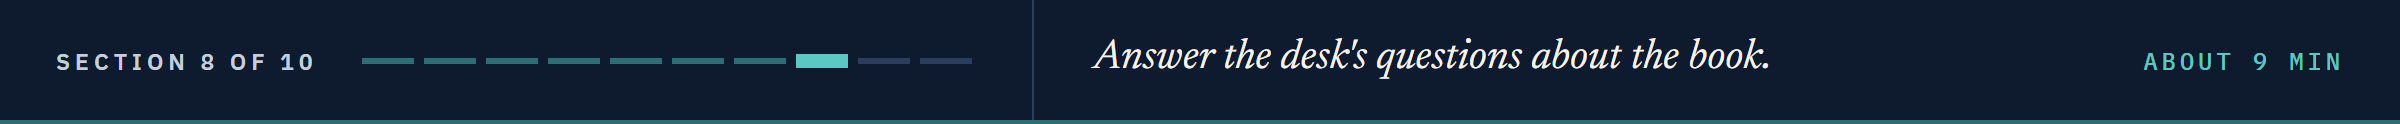

## 8 The Desk's Questions

The third sitting; a weight is a percent of the book's market value.

Tools: weights and the top ten (the Joining the Tables case study), weighted averages and `/ 365.25` (Combining Part 2), a signed bar (the Trade Blotter case study), a mean of 0s and 1s (the Consumer Credit case study).

**Excel side by side.** The corrected book, rows 2 to 207, DTS in column P; any current version.

<table align="left">
<tr><th align="left">Figure</th><th align="left">Excel</th></tr>
<tr><td align="left">A sector's weight</td><td align="left"><code>=SUMIF(E2:E207, "Materials", S2:S207) / SUM(S2:S207) * 100</code>, or a PivotTable value shown as % of Grand Total</td></tr>
<tr><td align="left">Weighted OAS</td><td align="left"><code>=SUMPRODUCT(M2:M207, S2:S207) / SUM(S2:S207)</code></td></tr>
<tr><td align="left">The book's DTS</td><td align="left"><code>=SUMPRODUCT(P2:P207, S2:S207) / SUM(S2:S207)</code></td></tr>
</table>
<br clear="left">

### 8.1 Weight by Sector, Bucket, and Grade

Q. Add `weight_pct` and check it adds to 100. Show bonds, value, and weight by sector, largest first, then by bucket and grade. Give the largest sector weight (**answer_8_1a**) and the High Yield weight (**answer_8_1b**) to 2 places.

In [33]:
# your code here
answer_8_1a = ...
answer_8_1b = ...

check('Question 8.1 largest sector', answer_8_1a, '2738459af618', places=2)
check('Question 8.1 High Yield', answer_8_1b, 'edaa9854371d', places=2)

Question 8.1 largest sector: not attempted yet
Question 8.1 High Yield: not attempted yet


#### Observations

*

### 8.2 The Ten Largest Issuers

Q. How many issuers are there, and which ten hold the most market value? What share are the ten, percent to 2 places (**answer_8_2**)?

In [34]:
# your code here
answer_8_2 = ...

check('Question 8.2', answer_8_2, 'd1a3b59754b2', places=2)

Question 8.2: not attempted yet


#### Observations

*

### 8.3 Weighted Averages

Q. Give the average coupon, OAS, duration, and score, simple and weighted by market value. Give the weighted OAS to 1 place (**answer_8_3a**) and duration to 2 (**answer_8_3b**).

In [35]:
# your code here
answer_8_3a = ...
answer_8_3b = ...

check('Question 8.3 weighted OAS', answer_8_3a, '5de1e801645c', places=1)
check('Question 8.3 weighted duration', answer_8_3b, '4f56fa36f714', places=2)

Question 8.3 weighted OAS: not attempted yet
Question 8.3 weighted duration: not attempted yet


#### Observations

*

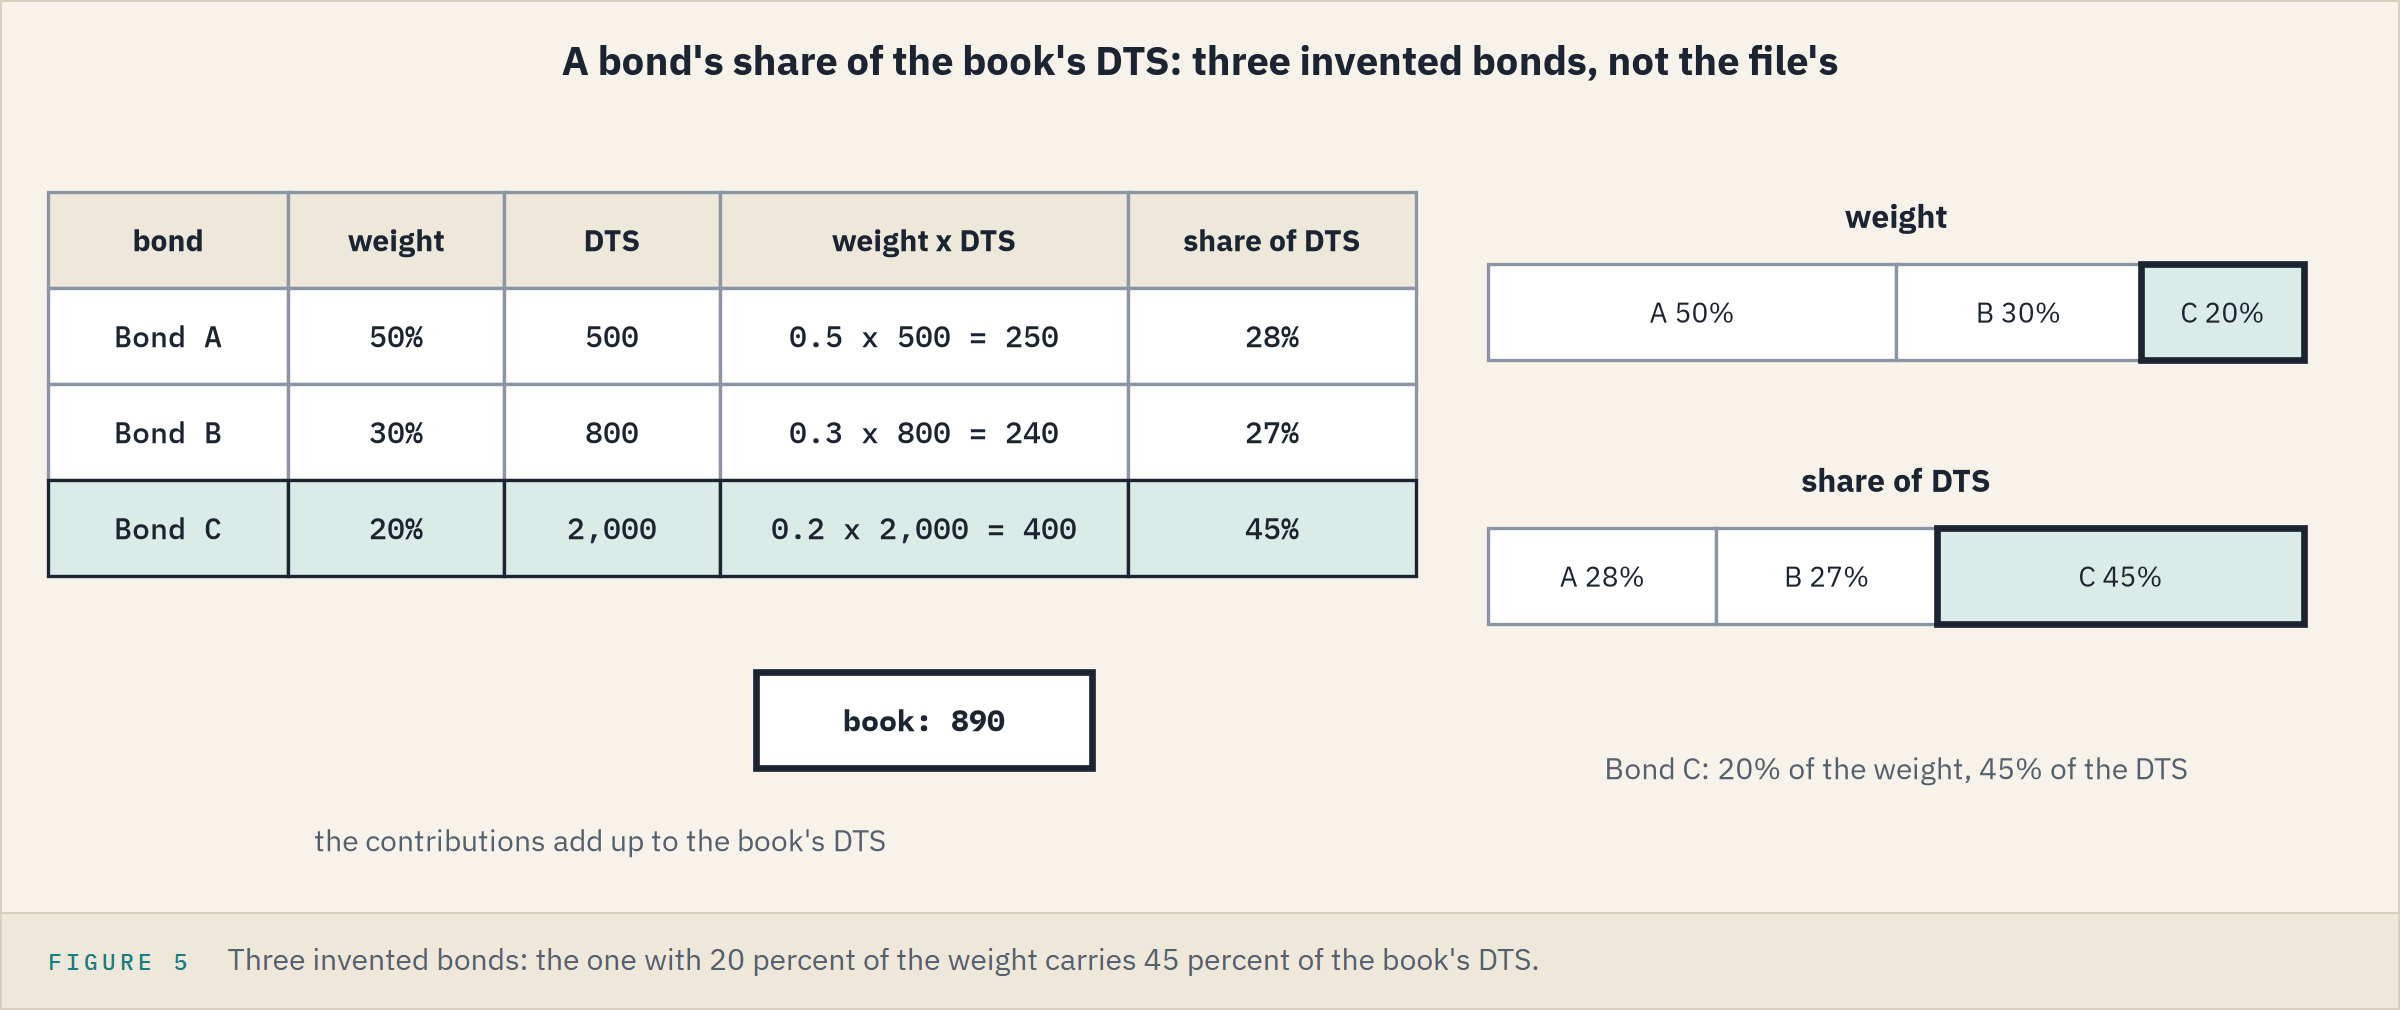

### 8.4 DTS by Sector

A bond's **DTS contribution** is its weight as a fraction times its DTS; the contributions add up to the book's DTS.

Q. Add `dts_contribution`, then show each sector's weight, contribution, and share of the book's DTS, largest first, and the same by grade. Give the book's DTS to 1 place (**answer_8_4**).

In [36]:
# your code here
answer_8_4 = ...

check('Question 8.4', answer_8_4, '835beb4d7b03', places=1)

Question 8.4: not attempted yet


#### Observations

*

### 8.5 Maturing Within Three Years

Q. Counting years as days to maturity over 365.25, what share of the book matures within three years, percent to 2 places (**answer_8_5**)?

In [37]:
# your code here
answer_8_5 = ...

check('Question 8.5', answer_8_5, '7aaf31349fc7', places=2)

Question 8.5: not attempted yet


#### Observations

*

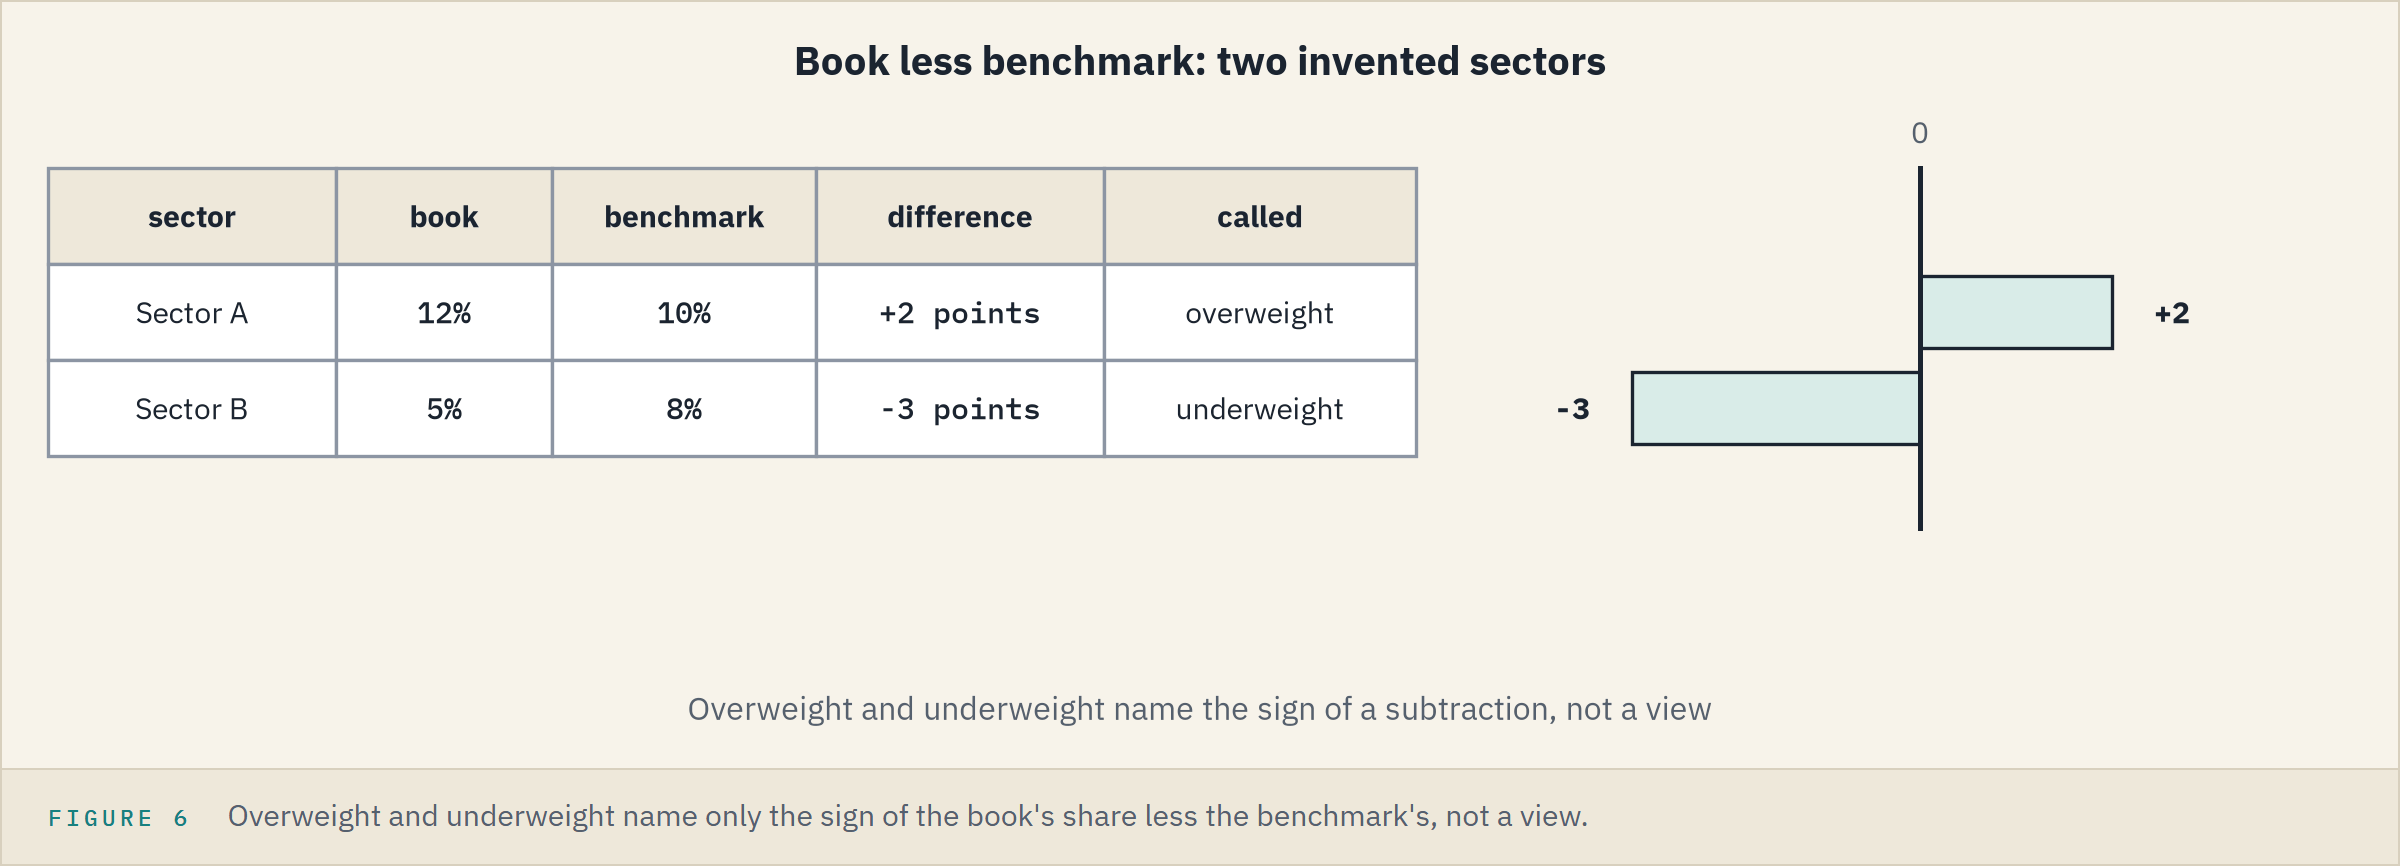

### 8.6 Book Less Benchmark, by Sector

A benchmark sector weight sums its bonds' `weight_pct`.
Positive is an **overweight** and negative an **underweight**: the sign of a subtraction, never a view.

Q. Show each sector's book weight, benchmark weight, and difference in percentage points, and draw the differences as bars with a zero line and a title naming both files' months. Give the largest positive difference's sector (**answer_8_6a**) and size to 2 places (**answer_8_6b**).

In [38]:
# your code here
answer_8_6a = ...
answer_8_6b = ...

check('Question 8.6 sector', answer_8_6a, 'e05a276ee4ce')
check('Question 8.6 difference', answer_8_6b, '94f45bd1b9ed', places=2)

Question 8.6 sector: not attempted yet
Question 8.6 difference: not attempted yet


#### Observations

*

### 8.7 Book Less Benchmark, by Bucket

Q. Join the scale to the benchmark, then compare by bucket in credit order and by grade, with the bucket differences drawn as bars. Give the BBB difference to 2 places (**answer_8_7**).

In [39]:
# your code here
answer_8_7 = ...

check('Question 8.7', answer_8_7, '0088be0fdc01', places=2)

Question 8.7: not attempted yet


#### Observations

*

### 8.8 The Ten Largest DTS Contributions

Q. Show the ten largest DTS contributions with CUSIP, ticker, rating, OAS, duration, DTS, and weight. Give their share of the book's DTS, percent to 1 place (**answer_8_8**), beside their weight.

In [40]:
# your code here
answer_8_8 = ...

check('Question 8.8', answer_8_8, '7e51df81fab2', places=1)

Question 8.8: not attempted yet


#### Observations

*

### 8.9 High Yield Share of Bonds, by Sector

Q. Add `is_hy`, 1 for High Yield and 0 otherwise, and show each sector's bonds and High Yield share of bonds, highest first. Give the top share to 1 place (**answer_8_9a**) and its bond count (**answer_8_9b**).

**Weights say where the dollars are; DTS shares say where the spread risk is.**

In [41]:
# your code here
answer_8_9a = ...
answer_8_9b = ...

check('Question 8.9 highest share', answer_8_9a, '11ebeef038cb', places=1)
check('Question 8.9 bonds', answer_8_9b, '0bbdc4781486', places=0)

Question 8.9 highest share: not attempted yet
Question 8.9 bonds: not attempted yet


#### Observations

*

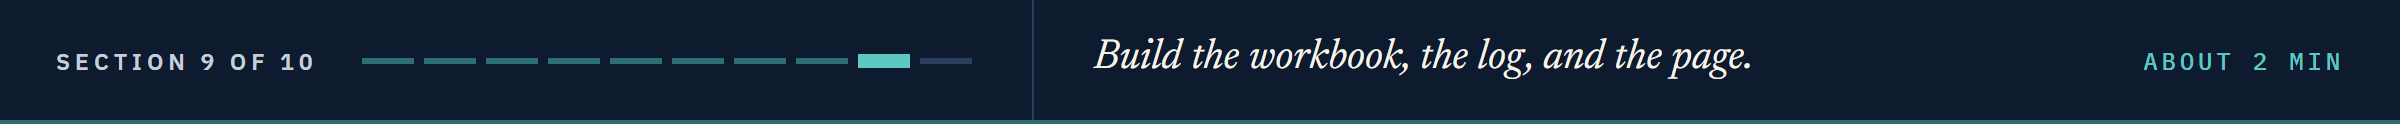

## 9 The Deliverables

Tools: `pd.ExcelWriter` and `read_excel(sheet_name=)` (Combining Part 2), the round trip (From Notebook to Module), `os.remove()` (week 1's Day 2).

### 9.1 The Workbook

Q. Write `project_report.xlsx`: a `book` sheet without row labels and a `summary` sheet of 8.1's sector table. Read both back into **answer_9_1a** and **answer_9_1b** as row counts, `assert` the book sheet's value, delete the file, and store whether it exists in **answer_9_1c**.

In [42]:
# your code here
answer_9_1a = ...
answer_9_1b = ...
answer_9_1c = ...

check('Question 9.1 book sheet', answer_9_1a, '15e830c9779f', places=0)
check('Question 9.1 summary sheet', answer_9_1b, '08f770846638', places=0)
check('Question 9.1 file left behind', answer_9_1c, '9c3d5c576030')

Question 9.1 book sheet: not attempted yet
Question 9.1 summary sheet: not attempted yet
Question 9.1 file left behind: not attempted yet


### 9.2 The AI-Use Log

Q. One row per question you asked an AI assistant; `none used` is valid.

Nothing from an employer, no client names, positions, or credentials, goes into an AI tool or Colab: describe the columns, not the rows, and follow your firm's policy first.

<table align="left">
<tr><th align="left">What I asked</th><th align="left">What I kept or rejected</th><th align="left">How I checked it</th></tr>
<tr><td align="left"></td><td align="left"></td><td align="left"></td></tr>
<tr><td align="left"></td><td align="left"></td><td align="left"></td></tr>
</table>
<br clear="left">

### 9.3 The Page

Q. Write the page for the portfolio manager below, 250 to 350 words, in five parts: the book in five numbers; concentrations by sector, grade, and issuer; data quality, each problem with its rows and its fix, and what was clean; the benchmark, with both files' dates; and open items for operations.

Describe, never recommend; give a number and its unit in almost every sentence.

*Write your page here.*

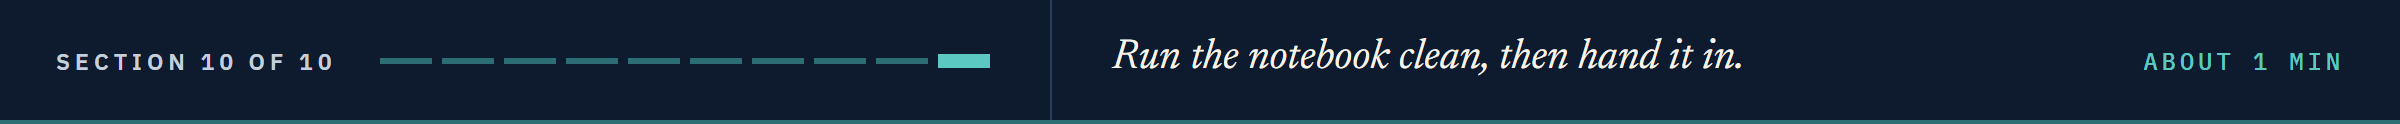

## Before You Hand In

Hand in this notebook, run from the top, with:

* every check `correct` and `raw` unchanged;
* a decision cell and headlines for every fix;
* `clean_extract` with its docstring and passing `assert`s;
* no `.xlsx` file left behind, and every chart finished;
* the log and the page.

The planted problems are in `data/project_answer_key.md`: read it after you finish.

## Congratulations!

The note is answered:

<table align="left">
<tr><th align="left">The note asked</th><th align="left">Where</th></tr>
<tr><td align="left">Can the file be trusted, and November in one call</td><td align="left">sections 3 and 4, <code>clean_extract</code></td></tr>
<tr><td align="left">What is in the book, and how it differs from the benchmark</td><td align="left">sections 5 to 8</td></tr>
<tr><td align="left">A workbook and one page</td><td align="left">9.1 and 9.3</td></tr>
</table>
<br clear="left">

At Day 0 you had never opened a notebook.

Since then you have learned to:

* read a traceback;
* filter, group, and join a book;
* draw a finished chart;
* test a file before trusting it;
* pull identifiers from text;
* keep a module, with tests;
* check an AI's code against your own number.

Be proud: you learned it one cell at a time.

Next is Course 2, Bond Math: prices, yields, duration, and DTS built by hand in your own `bondmath.py`, as you kept `desk_tools.py`.

[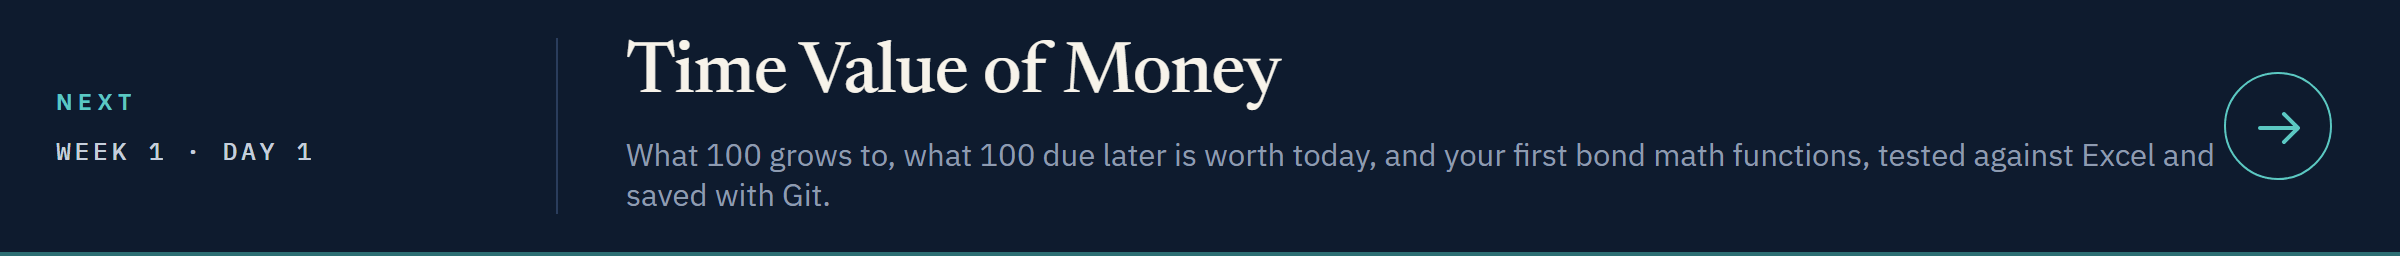](../../../course02_bond_math/week1/day1/01_time_value_of_money.ipynb)

[Open Day 1 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course02_bond_math/week1/day1/01_time_value_of_money.ipynb)